# Population dymanics response to parameters variation


The ODE system for tha population dynamics model is

\begin{equation}
\begin{aligned}
\dot{n}_5 &= \sigma P F(t)\, (N_{Yb} - n_5) - W_{51} (N_{Er} - n_2 - n_3) n_5 - W_{52} n_2 n_5 - k_{54} n_5
\\
\dot{n}_3 & = W_{52} n_2 n_5 - k_{31} n_3 + \sigma_{ESA} P F(t) x_2
\\
\dot{n}_2 & = W_{51} (N_{Er} - n_2 - n_3) n_5 - W_{52} n_2 n_5 - k_{21} n_2 - \sigma_{ESA} P F(t) n_2
\end{aligned} .
\end{equation}

We rescaled the populations in terms of the initial populations of the ground state $N = N_{Er} + N_{Yb}$. The time was rescaled by $\tau = 1/f$ and the rescaled ODE system is as follows:

\begin{aligned}
\dot{x_5}(\tau) &= \Pi F(\tau) (N_{Yb}/N - x_5) - W'_{51} (N_{Er}/N - x_2 - x_3) x_5 - W'_{52} x_2 x_5 - k'_{54} x*5
\\
\dot{x_3}(\tau) &= W'_{52} x_2 x_5 - k'_{31} x_3 + \Pi_{ESA} F(\tau) x_2
\\
\dot{x_2}(\tau) &= W'_{51} (N_{Er}/N - x_2 - x_3) x_5 - W'_{52} x_2 x_5 - k'_{21} x_2
\end{aligned},

where the rescaled radiative trasition rates are defined as $k'_{ji} = k_{ji}/f$ and the non-radiative transition rates are $W'_{ji} = W_{ji}N/f$.


#### Preamble and experimental data


In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.fft import fft, fftfreq
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from random import random
import os

# from treament_tcspc_data import fetch_data_filenames, extract_data_info_from_path, time_domain_visual_verification
# from snr_aux_functions import plot_time_and_freq_domain

In [2]:
# Phase difference list, processed previously from experiments
pd_list = np.load("./y2o3_yber_phase_diff.npy")
pd_labels = ["Y2O3: Yb/Er - 50mA", "Y2O3: Yb/Er - 200mA", "Y2O3: Yb/Er - 800mA"]

In [3]:
# --------------------------------------
# Estimations of n1 and n4
# --------------------------------------
dens_y2o3 = 5.010  # g/cm^3
massa_molar_y2o3 = 225.81  # g/mol
frac_er = 0.005  # Er3+ percentage in the sample
frac_yb = 0.015  # Yb3+ percentage in the sample

n1_0 = (
    (dens_y2o3 / massa_molar_y2o3) * (6.022e23) * 2 * (frac_er)
)  # number of Er3+ ions
n4_0 = (
    (dens_y2o3 / massa_molar_y2o3) * (6.022e23) * 2 * (frac_yb)
)  # number of Yb3+ ions

n0 = n1_0 + n4_0

In [4]:
# --------------------------------------
# Parameters
# --------------------------------------
k21 = 16.66  # s^-1, Tab. 2 em https://doi.org/10.1063/1.2739301
k31 = 17237.7  # s^-1
k54 = 1279.0  # Tab. 2 Lu0 em https://doi.org/10.1016/j.jallcom.2021.159227
sigma = 1.75e-20  # # Supporting Information, page S5, Labrador

P = 1e23  # The estimated value from experiment is 1e24 #Photons/(cm³ * s)
# P = 1e20#5.4e20    # photons / (cm^2 * s) (The value based on Labrador paper is for 110 W/cm^2  )

# ====================================================
# Some constants
# ====================================================
# ww51 = 1e-10#8.192933479247868e-09 # chute incial
# ww52 = 1e-10#1.9970817793515877e-07 # chute inicial
ww51 = 1.0e-11
ww52 = 1.0e-11
# ====================================================

# ====================================================
# Excitation modulation paramenters
# ====================================================
amplitude = 0.3
offset = 0.5
# ====================================================

num_points = 24

In [5]:
# --------------------------------------
# Estimations of n1 and n4
# --------------------------------------
dens_y2o3 = 5.010  # g/cm^3
massa_molar_y2o3 = 225.81  # g/mol
frac_er = 0.005  # Er3+ percentage in the sample
frac_yb = 0.020  # Yb3+ percentage in the sample

n1_0 = (
    (dens_y2o3 / massa_molar_y2o3) * (6.022e23) * 2 * (frac_er)
)  # number of Er3+ ions
n4_0 = (
    (dens_y2o3 / massa_molar_y2o3) * (6.022e23) * 2 * (frac_yb)
)  # number of Yb3+ ions

n0 = n1_0 + n4_0

# ====================================================
# Estimation of k21 and k31
# ====================================================
k21 = 1.5e2 + 448  # s^-1      (Tab. 3 Perrin)
k_cr50 = 4.9e-17  # cm^3 * s^-1      (Tab. 3 Perrin)
k_bt51 = 1.8e-17  # cm^3 * s^-1      (Tab. 3 Perrin)
k31 = 9.8e2 + 4.2e2 + 5.5e3 + k_cr50 * n1_0 + k_bt51 * n4_0

# ====================================================
# Estimation of k54
# ====================================================
k1p0p = 173.0  # s^-1      (Tab. 3 Perrin)
kET_d = 2.2e-18  # cm^3 s^-1 (Tab. 3 Perrin)
k54 = k1p0p + kET_d * n4_0

# ====================================================
# Some constants
# ====================================================
# ww51 = 1e-10#8.192933479247868e-09 # chute incial
# ww52 = 1e-10#1.9970817793515877e-07 # chute inicial
ww51 = 1e-17
ww52 = 1e-17

# ====================================================
# Initial fixed parameters
# ====================================================
k21_initial = 598.0  # *0.1
k31_initial = 7688.9  # para er apenas k31 ~ 7688.9, por isso não utilizarei 23066.7
k54_initial = 1348.8  # *0.1
P_initial = (200 / 150) * (6e22)  # para o er a 150mA P ~ 6e22
ww51_initial = 1.0e-17
ww52_initial = 1.0e-17

sigma_esa = 1e-23

In [6]:
# Funtion to extract the phase via FFT
def extrair_fase(t, n3, freq):
    """Time must be in seconds and frequency in Hertz"""
    # DICA CRUCIAL: Descartar a primeira metade da simulação (o transiente)
    # Analisamos apenas a parte onde a onda já estabilizou
    meio = len(t) // 2
    t_estavel = t[meio:]
    n3_estavel = n3[meio:]

    # Recria o sinal do laser no mesmo intervalo de tempo para comparação
    laser_estavel = offset + amplitude * np.cos(2 * np.pi * freq * t_estavel)

    N = len(t_estavel)
    dt = t_estavel[1] - t_estavel[0]

    # Aplica a FFT
    yf_n3 = fft(n3_estavel)
    yf_laser = fft(laser_estavel)
    xf = fftfreq(N, dt)

    # Encontra o índice da frequência de modulação (freq) no array da FFT
    idx = np.argmin(np.abs(xf - freq))

    # Extrai o ângulo (fase) de ambos os sinais nesse pico de frequência
    fase_n3 = np.angle(yf_n3[idx])
    fase_laser = np.angle(yf_laser[idx])

    # Diferença de fase (Luminescência - Laser)
    delta_fase = fase_n3 - fase_laser

    # Garante que o valor fique no intervalo correto [-pi, pi]
    delta_fase = np.angle(np.exp(1j * delta_fase))

    return delta_fase


# Funtion to extract amplitudes via FFT
def get_fft_amp(t, n3, freq):
    """Return the Fourier complex amplitude modulus for the chosen frequency. \n
    Time must be in seconds and frequency in Hertz."""
    # DICA CRUCIAL: Descartar a primeira metade da simulação (o transiente)
    # Analisamos apenas a parte onde a onda já estabilizou
    meio = len(t) // 2
    t_estavel = t[meio:]
    n3_estavel = n3[meio:]

    N = len(t_estavel)
    dt = t_estavel[1] - t_estavel[0]

    # Aplica a FFT
    yf_n3 = fft(n3_estavel)
    xf = fftfreq(N, dt)

    # Encontra o índice da frequência de modulação (freq) no array da FFT
    idx = np.argmin(np.abs(xf - freq))

    return np.abs(yf_n3[idx])


# Define system
def odes(t, x, W51, W52, ks, sigma_esa, P, f):
    k21, k31, k54 = ks
    # The 't' here represents the dimensionless variable tau (tau = t*f)
    x2, x3, x5 = x
    n0_er = n1_0 / n0
    n0_yb = n4_0 / n0

    # Laser function according to previously defined settings
    F_t = offset + amplitude * np.cos(2 * np.pi * t)

    # Numerical safeguard: intensity cannot be negative.
    if F_t < 0:
        F_t = 0.0

    # Yb3+ populations
    dx5_dt = (
        (sigma * P / f) * F_t * (n0_yb - x5)
        - (W51 * n0 / f) * x5 * (n0_er - x2 - x3)
        - (W52 * n0 / f) * x5 * x2
        - (k54 / f) * x5
    )

    # Er3+ populations
    dx3_dt = (W52 * n0 / f) * x5 * x2 - (k31 / f) * x3 + (sigma_esa * P / f) * F_t * x2
    dx2_dt = (
        (W51 * n0 / f) * x5 * (n0_er - x2 - x3)
        - (W52 * n0 / f) * x5 * x2
        - (k21 / f) * x2
        - (sigma_esa * P / f) * F_t * x2
    )

    return [dx2_dt, dx3_dt, dx5_dt]

#### Fitting $W_{51}$, $W_{52}$ and $k_{31}$


##### Fitting


In [ ]:
ww51 = ww51_initial
ww52 = ww52_initial
k21 = k21_initial
k31 = k31_initial
k54 = k54_initial
P = P_initial

exp_to_compare = 1

# ---> AJUSTE DE W51, W52 E k31 (únicos parâmetros livres) <---
frequencias_ajuste = pd_list[exp_to_compare][:num_points, 0]
fases_ajuste = pd_list[exp_to_compare][:num_points, 1]
incertezas_ajuste = pd_list[exp_to_compare][
    :num_points, 2
]  # barra de erro da fase (rad)


def residuos_W_k31(log_p):
    """Resíduo entre a fase simulada e a experimental. O ajuste é feito em log10(W51, W52, k31)."""
    W51_fit, W52_fit, k31_fit = 10**log_p
    fases_sim = []
    for f in frequencias_ajuste:
        t_eval = np.linspace(0, 200, 10000)
        sol = solve_ivp(
            odes,
            (0, 200),
            [0, 0, 0],
            t_eval=t_eval,
            args=(W51_fit, W52_fit, [k21, k31_fit, k54], sigma_esa, P, f),
            method="Radau",
        )
        fases_sim.append(extrair_fase(sol.t / f, sol.y[1] * n0, f))
    fases_sim = np.unwrap(np.array(fases_sim))
    # Diferença reembrulhada em [-pi, pi] (evita penalizar saltos de 2*pi), ponderada pela incerteza
    return np.angle(np.exp(1j * (fases_sim - fases_ajuste))) / incertezas_ajuste


chute_inicial = np.log10([1e-17, 1e-17, 1e4])  # w51 = w52 = 1e-17, k31 = 7.6e3

ajuste = least_squares(
    residuos_W_k31,
    chute_inicial,
    bounds=([-22, -22, 2], [-8, -8, 6]),
    diff_step=5e-3,
    verbose=2,
)

ww51_fit, ww52_fit, k31_fit = 10**ajuste.x
print(f"W51 ajustado = {ww51_fit:.3e} cm^3/s")
print(f"W52 ajustado = {ww52_fit:.3e} cm^3/s")
print(f"k31 ajustado = {k31_fit:.3e} s^-1")
print(
    f"RMS do resíduo = {np.rad2deg(np.sqrt(np.mean((ajuste.fun*incertezas_ajuste)**2))):.2f} graus"
)
print(
    f"Qui-quadrado reduzido = {np.sum(ajuste.fun**2)/(len(ajuste.fun) - len(ajuste.x)):.2f}"
)

##### Plots


In [ ]:
fig, axs = plt.subplots(3, 2, figsize=(15, 15))

# ---> LISTA NOVA PARA ARMAZENAR OS DADOS DE 1kHz <---
dados_1kHz = []


# Compara o chute inicial com o resultado do ajuste
params = [
    [ww51_initial, ww52_initial, k21, 7.6e3, k54, P_initial],
    [ww51_fit, ww52_fit, k21, k31_fit, k54, P_initial],
]

for idx, param in enumerate(params):
    # if idx != 1: continue # Apenas parametro inicial
    ww51, ww52, k21, k31, k54, P = param
    print("=" * 30)
    print(f"k21 = {k21:.2e}")
    print(f"k31 = {k31:.2e}")
    print(f"k54 = {k54:.2e}")
    print(f"w51 = {ww51:.2e}")
    print(f"w52 = {ww52:.2e}")
    print(f"sigma_esa = {sigma_esa:.2e}")
    print(f"P = {P:.2e}")
    print("=" * 30)

    plts_label = f"W51={ww51:.1e}, W52={ww52:.1e}, k31={k31:.1e}"

    fases_calculadas = []

    for sample_id, pd in enumerate(pd_list):
        if sample_id != exp_to_compare:
            continue

        frequencias_experimentais = pd[:num_points, 0]
        fases_experimentais = pd[:num_points, 1]
        W51, W52 = ww51, ww52
        sol_to_plot = []
        amps_list = []
        amps_list_2omega = []

        for f in frequencias_experimentais:
            # Simula 200 ciclos em tempo adimensional para garantir que o transiente morra
            t_span = (0, 200)
            t_eval = np.linspace(t_span[0], t_span[1], 10000)
            sol = solve_ivp(
                odes,
                t_span,
                [0, 0, 0],  # x2 x3 x5 @ t=0
                t_eval=t_eval,
                args=(W51, W52, [k21, k31, k54], sigma_esa, P, f),
                method="Radau",  # Mantendo o método Radau que demonstrou estabilidade acima
            )
            # Converte de volta para unidades físicas antes de extrair a fase
            n3 = (sol.y[1]) * n0
            ts = (sol.t) * (1 / f)
            n2 = (sol.y[0]) * n0

            if f == 1000:
                sol_to_plot = [ts, n2, n3]
                # ---> SALVANDO SINAL PARA A NOVA FIGURA <---
                dados_1kHz.append((ts, n3, W51, plts_label))

            fase_calc = extrair_fase(ts, n3, f)
            fases_calculadas.append(fase_calc)
            amps_list.append(get_fft_amp(ts, n3, f))
            amps_list_2omega.append(get_fft_amp(ts, n3, 2 * f))

        fases_calculadas = np.unwrap(np.array(fases_calculadas))
        amps_list = np.array(amps_list)
        powers = amps_list**2

        amps_list_2omega = np.array(amps_list_2omega)

        amps_2omega_ad = [
            amps_list_2omega[i] / amps_list[i] for i in range(len(amps_list))
        ]
        amps_2omega_ad = np.array(amps_2omega_ad)

        powers_2omega = amps_list_2omega**2
        powers_2omega_ad = amps_2omega_ad**2

        # Phase lag plot
        if idx == 0:
            axs[0, 0].plot(
                frequencias_experimentais,
                np.rad2deg(fases_experimentais),
                "o-",
                color="gray",
                label=f"{pd_labels[sample_id]}",
            )

        axs[0, 0].plot(
            frequencias_experimentais,
            np.rad2deg(fases_calculadas),
            "o-",
            label="sim (" + plts_label + ")",
        )
        axs[0, 0].hlines(
            -180,
            xmin=0,
            xmax=frequencias_experimentais[-1],
            linestyles="--",
            colors="gray",
        )
        axs[0, 0].hlines(
            -90,
            xmin=0,
            xmax=frequencias_experimentais[-1],
            linestyles="--",
            colors="gray",
        )
        axs[0, 0].set_xscale("log")
        axs[0, 0].set_ylabel("$\Delta \phi$ (deg)")
        axs[0, 0].set_xlabel("Frequency (Hz)")
        axs[0, 0].set_title("Phase lag")

        # Population time evolution @ 1kHz
        ts, n2, n3 = sol_to_plot
        (linha,) = axs[0, 1].plot(
            ts, n2 / n0, linestyle="--", label="$n_2$ (" + plts_label + ")"
        )
        axs[0, 1].plot(
            ts, n3 / n0, color=linha.get_color(), label="$n_3$ (" + plts_label + ")"
        )
        axs[0, 1].set_ylabel("Population density (cm$^{-3}$)")
        axs[0, 1].set_xlabel("Time (s)")
        axs[0, 1].set_xlim([0, ts[int(len(ts) * (0.02))]])
        axs[0, 1].set_title("Population dynamics at 1kHz")

        # Amplitudes plot
        axs[1, 0].scatter(
            frequencias_experimentais,
            amps_list / amps_list.max(),
            label="sim (" + plts_label + ")",
        )
        axs[1, 0].set_ylabel("$|A(\omega)|$")
        axs[1, 0].set_xlabel("Frequency (Hz)")
        axs[1, 0].set_xscale("log")
        axs[1, 0].set_title("Fourier amplitude modulus")

        # Power plot
        axs[1, 1].scatter(
            frequencias_experimentais,
            powers / (powers).max(),
            label="sim (" + plts_label + ")",
        )
        axs[1, 1].set_ylabel("Power ($\propto |A(\omega)|^2$)")
        axs[1, 1].set_xlabel("Frequency (Hz)")
        axs[1, 1].set_xscale("log")
        axs[1, 1].set_title("Power spectrum")

        # Amplitudes plot for 2omega
        axs[2, 0].scatter(
            frequencias_experimentais, amps_2omega_ad, label="sim (" + plts_label + ")"
        )
        axs[2, 0].set_ylabel("$|A(2\omega)/A(\omega)|$")
        axs[2, 0].set_xlabel("Frequency (Hz)")
        axs[2, 0].set_xscale("log")
        axs[2, 0].set_title("Fourier amplitude modulus of $2\omega$")

        # Power plot for 2omega
        axs[2, 1].scatter(
            frequencias_experimentais,
            powers_2omega_ad,
            label="sim (" + plts_label + ")",
        )
        axs[2, 1].set_ylabel("$|A(2\omega)/A(\omega)|^2$")
        axs[2, 1].set_xlabel("Frequency (Hz)")
        axs[2, 1].set_xscale("log")
        axs[2, 1].set_title("Power spectrum of $2\omega$")

axs[0, 0].legend()
axs[0, 1].legend()
axs[1, 0].legend()
axs[1, 1].legend()
axs[2, 0].legend()
axs[2, 1].legend()
fig.tight_layout()


# ---> CRIAÇÃO DA NOVA FIGURA PARA O ESPECTRO DE 1kHz <---
fig2, axs2 = plt.subplots(2, 1, figsize=(10, 8))

for ts_1k, n3_1k, w1k_val, plt_label_1k in dados_1kHz:
    # 1. Domínio do tempo
    # Plotamos os últimos 4 ciclos (200 pontos no total, pois são 50 pts por ciclo)
    # Isso evita ver um bloco maciço de 200 ciclos e foca no regime estacionário
    axs2[0].plot(ts_1k[-200:], n3_1k[-200:], label=plt_label_1k)

    # 2. Domínio da frequência (Espectro de Potência)
    # Utilizamos a segunda metade do sinal para evitar vazamento espectral dos transientes
    meio = len(ts_1k) // 2
    ts_estacionario = ts_1k[meio:]
    n3_estacionario = n3_1k[meio:]

    N = len(ts_estacionario)
    dt = ts_estacionario[1] - ts_estacionario[0]

    yf = fft(n3_estacionario)
    xf = fftfreq(N, dt)

    # Filtro para pegar apenas frequências positivas (remove a componente DC em 0 Hz)
    idx_pos = xf > 0
    xf_pos = xf[idx_pos]
    power = np.abs(yf[idx_pos]) ** 2

    axs2[1].plot(xf_pos, power / power.max(), label=plt_label_1k)

axs2[0].set_title("(a) Number of counts in the time domain (Steady state)")
axs2[0].set_xlabel("Time (s)")
axs2[0].set_ylabel("Population density $n_3$ (cm$^{-3}$)")
axs2[0].legend(loc="upper right")

axs2[1].set_title("(b) Signal power representation in the frequency domain")
axs2[1].set_xlabel("Frequency (Hz)")
axs2[1].set_ylabel("Power")
axs2[1].set_xlim(
    [0, 10000]
)  # Foca nos harmônicos até 10kHz conforme sua imagem de referência
axs2[1].legend(loc="upper right")
fig2.tight_layout()

# O plt.show() agora vai renderizar ambas as janelas (fig e fig2)
plt.show()

#### Joint fit of the three powers ($W_{51}$, $W_{52}$ and $k_{31}$ shared)

##### Fitting

In [7]:
ww51 = ww51_initial
ww52 = ww52_initial
k21 = k21_initial
k31 = k31_initial
k54 = k54_initial
P = P_initial

# ---> AJUSTE CONJUNTO DAS 3 POTÊNCIAS: W51, W52*c, k31, c E sigma_esa*c (parâmetros livres, compartilhados) <---
correntes = [50, 200, 800]  # mA, na mesma ordem de pd_labels
P_list = [P_initial * c / 200 for c in correntes]  # supõe P proporcional à corrente (P_initial em 200 mA)

frequencias_conj = [pd[:num_points, 0] for pd in pd_list]
fases_conj = [pd[:num_points, 1] for pd in pd_list]
incertezas_conj = [pd[:num_points, 2] for pd in pd_list]  # barra de erro da fase (rad)


def residuos_conjunto(log_p):
    """Resíduos das 3 potências concatenados. O ajuste é feito em log10(W51, W52*c, k31, c, sigma_esa*c)."""
    W51_fit, W52c_fit, k31_fit, c_fit, sigmac_fit = 10**log_p  # <- produtos W52*c e sigma_esa*c
    W52_fit = W52c_fit / c_fit  # <- recupera W52
    sigma_esa_fit = sigmac_fit / c_fit  # <- recupera sigma_esa
    residuos = []
    for freqs, fases_exp, incs, P_amostra in zip(
        frequencias_conj, fases_conj, incertezas_conj, P_list
    ):
        fases_sim = []
        for f in freqs:
            t_eval = np.linspace(0, 200, 10000)
            sol = solve_ivp(
                odes,
                (0, 200),
                [0, 0, 0],
                t_eval=t_eval,
                args=(W51_fit, W52_fit, [k21, k31_fit, k54], sigma_esa_fit, c_fit * P_amostra, f),
                method="Radau",
                atol=1e-10,
                rtol=1e-6,
            )
            fases_sim.append(extrair_fase(sol.t / f, sol.y[1] * n0, f))
        fases_sim = np.unwrap(np.array(fases_sim))
        # Diferença reembrulhada em [-pi, pi] (evita penalizar saltos de 2*pi), ponderada pela incerteza
        residuos.append(np.angle(np.exp(1j * (fases_sim - fases_exp))) / incs)
    return np.concatenate(residuos)

# chute_inicial = np.log10([5.331e-18, 7.412e-17, 8.324e4, 4.337e-2, 1e-21])  # <- último ajuste + sigma_esa = 1e-21
# chute_inicial = np.log10([5.331e-18, 7.412e-17, 8.324e4, 0.2, 1e-19])  # <- último ajuste + sigma_esa = 1e-21
# chute_inicial = np.log10([5.331e-18, 7.412e-17, 8.324e4, 4.337e-2, 1e-19])  # <- último ajuste + sigma_esa = 1e-21
chute_inicial = np.log10(
    [5.998e-18, 6.636e-17 * 4.365e-2, 4.380e4, 4.365e-2, 5.308e-21 * 4.365e-2]
)  # <- último ajuste, na forma (W51, W52*c, k31, c, sigma_esa*c)

ajuste_conj = least_squares(
    residuos_conjunto,
    chute_inicial,
    bounds=([-22, -25, 2, -3, -28], [-8, -7, 6, 1, -16]),  # <- limites de W52*c e sigma_esa*c
    diff_step=5e-3,
    verbose=2,
    workers=5,   # <- avalia as 5 colunas do jacobiano em paralelo
)

ww51_fit_conj, W52c_fit_conj, k31_fit_conj, c_fit_conj, sigmac_fit_conj = 10**ajuste_conj.x  # <- produtos
ww52_fit_conj = W52c_fit_conj / c_fit_conj  # <- recupera W52 (usado nos gráficos)
sigma_esa_fit_conj = sigmac_fit_conj / c_fit_conj  # <- recupera sigma_esa (usado nos gráficos)
print(f"W51 ajustado = {ww51_fit_conj:.3e} cm^3/s")
print(f"W52*c ajustado = {W52c_fit_conj:.3e} cm^3/s")  # <- novo
print(f"sigma_esa*c ajustado = {sigmac_fit_conj:.3e} cm^2")  # <- novo
print(f"k31 ajustado = {k31_fit_conj:.3e} s^-1")
print(f"c ajustado = {c_fit_conj:.3e}  ->  P = {[f'{c_fit_conj*p:.2e}' for p in P_list]}")
print(f"  (W52 = {ww52_fit_conj:.3e} cm^3/s, sigma_esa = {sigma_esa_fit_conj:.3e} cm^2)")  # <- valores separados
print(
    f"Qui-quadrado reduzido (total) = {np.sum(ajuste_conj.fun**2)/(len(ajuste_conj.fun) - len(ajuste_conj.x)):.2f}"
)
# Resíduo separado por potência
inicio = 0
for label, incs in zip(pd_labels, incertezas_conj):
    r = ajuste_conj.fun[inicio : inicio + len(incs)]
    inicio += len(incs)
    print(
        f"{label}: RMS = {np.rad2deg(np.sqrt(np.mean((r*incs)**2))):.2f} graus, qui-quadrado/ponto = {np.mean(r**2):.2f}"
    )

sigma_esa = sigma_esa_fit_conj  # <- para a célula de gráficos usar o valor ajustado

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         7.1512e+03                                    2.39e+03    
       1              2         6.8428e+03      3.08e+02       9.38e-01       4.15e+04    
       2              3         6.7241e+03      1.19e+02       6.05e-01       9.97e+03    
       3              4         6.6711e+03      5.31e+01       1.08e-01       1.06e+04    
       4              5         6.6268e+03      4.43e+01       2.98e-02       9.78e+03    
       5              6         6.5861e+03      4.07e+01       2.86e-02       9.46e+03    
       6              7         6.5461e+03      4.01e+01       2.92e-02       9.56e+03    
       7              8         6.5043e+03      4.18e+01       3.09e-02       1.00e+04    
       8              9         6.4588e+03      4.55e+01       3.41e-02       1.08e+04    
       9             10         6.4075e+03      5.13e+01       3.90e-02       1.18e+04    

In [8]:
J = ajuste_conj.jac
chi2_red = np.sum(ajuste_conj.fun**2) / (len(ajuste_conj.fun) - len(ajuste_conj.x))
cov = np.linalg.inv(J.T @ J) * chi2_red
err = np.sqrt(np.diag(cov))
corr = cov / np.outer(err, err)
nomes = ["W51", "W52*c", "k31", "c", "sigma_esa*c"]
print("incerteza (em décadas, log10):", dict(zip(nomes, np.round(err, 3))))
print(np.round(corr, 2))

incerteza (em décadas, log10): {'W51': np.float64(0.07), 'W52*c': np.float64(0.077), 'k31': np.float64(0.063), 'c': np.float64(18.398), 'sigma_esa*c': np.float64(18314.157)}
[[ 1.   -0.9  -0.28 -0.85  0.01]
 [-0.9   1.    0.16  0.68  0.01]
 [-0.28  0.16  1.    0.12 -0.39]
 [-0.85  0.68  0.12  1.    0.01]
 [ 0.01  0.01 -0.39  0.01  1.  ]]


##### Plots

k21 = 5.98e+02
k31 = 1.08e+05
k54 = 1.35e+03
w51 = 3.14e-18
w52 = 8.51e-15
sigma_esa = 1.16e-24
P = ['2.00e+22', '8.00e+22', '3.20e+23']


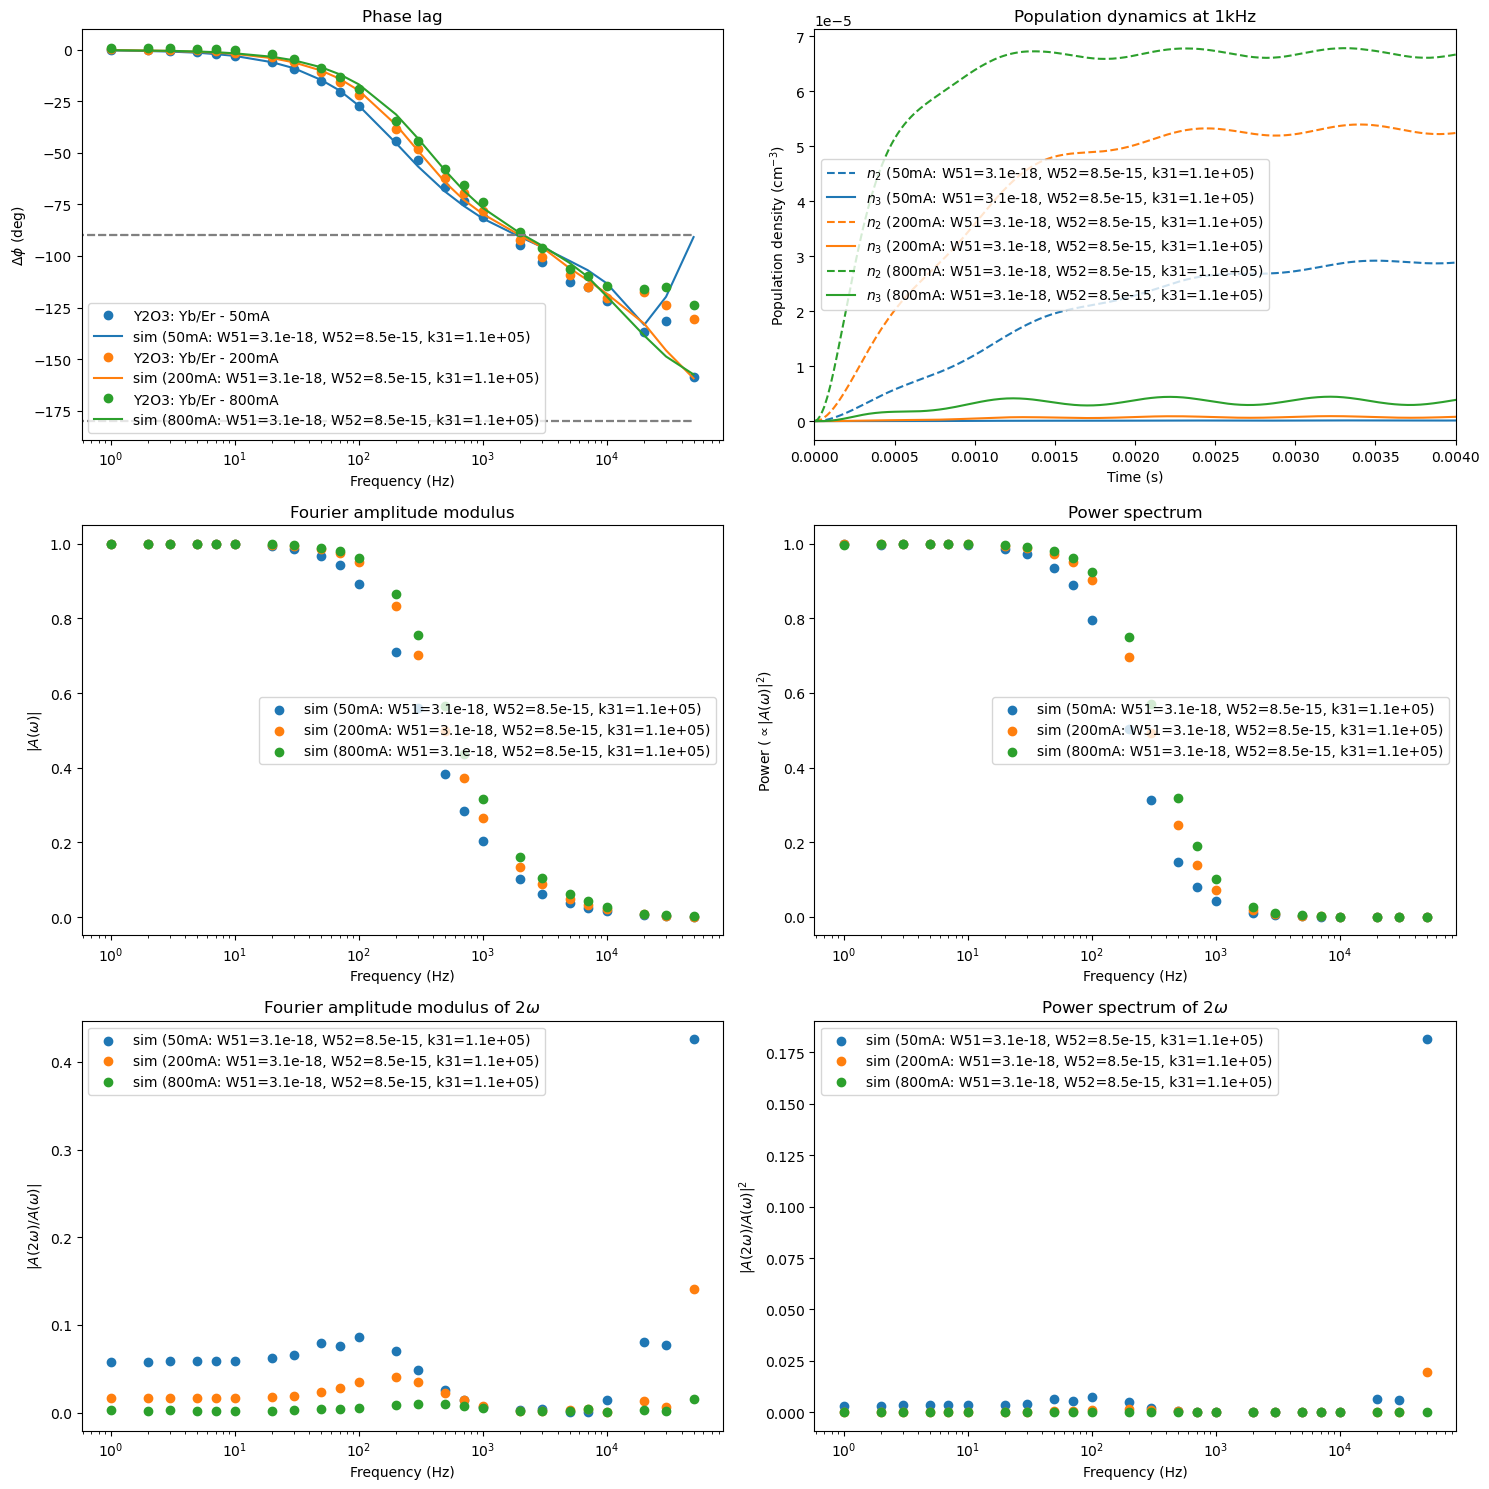

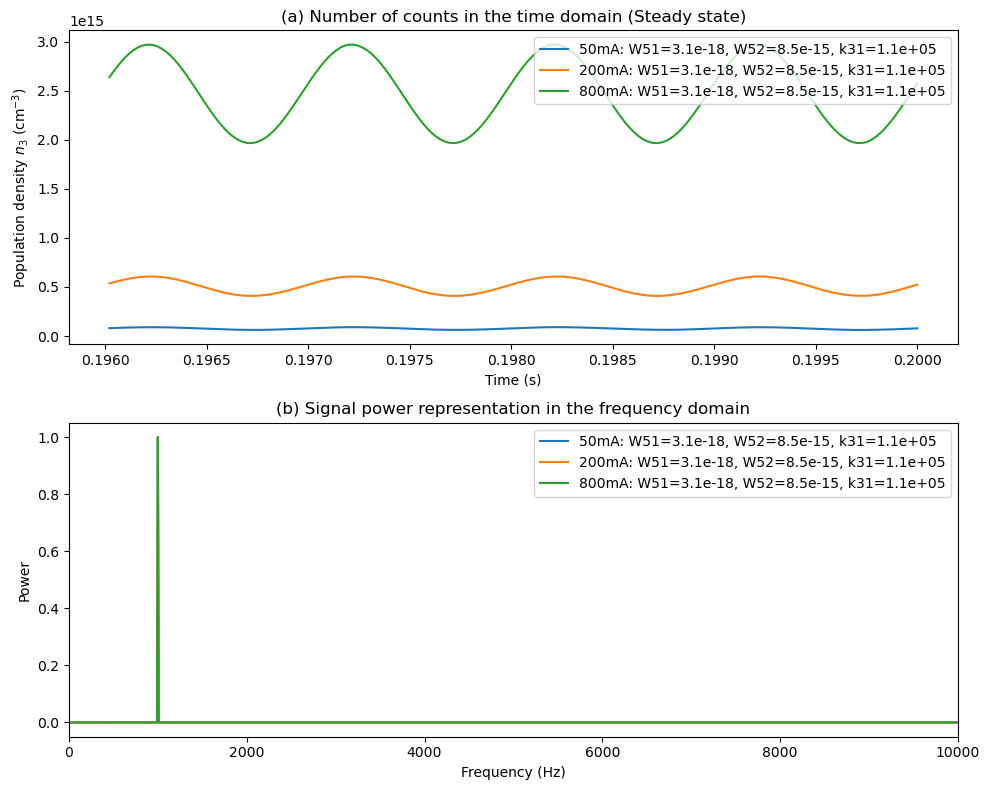

In [9]:
fig, axs = plt.subplots(3, 2, figsize=(15, 15))

# ---> LISTA NOVA PARA ARMAZENAR OS DADOS DE 1kHz <---
dados_1kHz = []

# Resultado do ajuste conjunto (P de cada curva vem de P_list)
params = [
    [ww51_fit_conj, ww52_fit_conj, k21, k31_fit_conj, k54, P_initial],
]

for idx, param in enumerate(params):
    # if idx != 1: continue # Apenas parametro inicial
    ww51, ww52, k21, k31, k54, P = param
    print("=" * 30)
    print(f"k21 = {k21:.2e}")
    print(f"k31 = {k31:.2e}")
    print(f"k54 = {k54:.2e}")
    print(f"w51 = {ww51:.2e}")
    print(f"w52 = {ww52:.2e}")
    print(f"sigma_esa = {sigma_esa:.2e}")
    print(f"P = {[f'{p:.2e}' for p in P_list]}")
    print("=" * 30)

    for sample_id, pd in enumerate(pd_list):
        P = c_fit_conj*P_list[sample_id]
        plts_label = f"{correntes[sample_id]}mA: W51={ww51:.1e}, W52={ww52:.1e}, k31={k31:.1e}"
        fases_calculadas = []

        frequencias_experimentais = pd[:num_points, 0]
        fases_experimentais = pd[:num_points, 1]
        W51, W52 = ww51, ww52
        sol_to_plot = []
        amps_list = []
        amps_list_2omega = []

        for f in frequencias_experimentais:
            # Simula 200 ciclos em tempo adimensional para garantir que o transiente morra
            t_span = (0, 200)
            t_eval = np.linspace(t_span[0], t_span[1], 10000)
            sol = solve_ivp(
                odes,
                t_span,
                [0, 0, 0],  # x2 x3 x5 @ t=0
                t_eval=t_eval,
                args=(W51, W52, [k21, k31, k54], sigma_esa, P, f),
                method="Radau",  # Mantendo o método Radau que demonstrou estabilidade acima
            )
            # Converte de volta para unidades físicas antes de extrair a fase
            n3 = (sol.y[1]) * n0
            ts = (sol.t) * (1 / f)
            n2 = (sol.y[0]) * n0

            if f == 1000:
                sol_to_plot = [ts, n2, n3]
                # ---> SALVANDO SINAL PARA A NOVA FIGURA <---
                dados_1kHz.append((ts, n3, W51, plts_label))

            fase_calc = extrair_fase(ts, n3, f)
            fases_calculadas.append(fase_calc)
            amps_list.append(get_fft_amp(ts, n3, f))
            amps_list_2omega.append(get_fft_amp(ts, n3, 2 * f))

        fases_calculadas = np.unwrap(np.array(fases_calculadas))
        amps_list = np.array(amps_list)
        powers = amps_list**2

        amps_list_2omega = np.array(amps_list_2omega)

        amps_2omega_ad = [
            amps_list_2omega[i] / amps_list[i] for i in range(len(amps_list))
        ]
        amps_2omega_ad = np.array(amps_2omega_ad)

        powers_2omega = amps_list_2omega**2
        powers_2omega_ad = amps_2omega_ad**2

        # Phase lag plot
        if idx == 0:
            (linha_exp,) = axs[0, 0].plot(
                frequencias_experimentais,
                np.rad2deg(fases_experimentais),
                "o",
                label=f"{pd_labels[sample_id]}",
            )

        axs[0, 0].plot(
            frequencias_experimentais,
            np.rad2deg(fases_calculadas),
            "-",
            color=linha_exp.get_color(),
            label="sim (" + plts_label + ")",
        )
        axs[0, 0].hlines(
            -180,
            xmin=0,
            xmax=frequencias_experimentais[-1],
            linestyles="--",
            colors="gray",
        )
        axs[0, 0].hlines(
            -90,
            xmin=0,
            xmax=frequencias_experimentais[-1],
            linestyles="--",
            colors="gray",
        )
        axs[0, 0].set_xscale("log")
        axs[0, 0].set_ylabel("$\Delta \phi$ (deg)")
        axs[0, 0].set_xlabel("Frequency (Hz)")
        axs[0, 0].set_title("Phase lag")

        # Population time evolution @ 1kHz
        ts, n2, n3 = sol_to_plot
        (linha,) = axs[0, 1].plot(
            ts, n2 / n0, linestyle="--", label="$n_2$ (" + plts_label + ")"
        )
        axs[0, 1].plot(
            ts, n3 / n0, color=linha.get_color(), label="$n_3$ (" + plts_label + ")"
        )
        axs[0, 1].set_ylabel("Population density (cm$^{-3}$)")
        axs[0, 1].set_xlabel("Time (s)")
        axs[0, 1].set_xlim([0, ts[int(len(ts) * (0.02))]])
        axs[0, 1].set_title("Population dynamics at 1kHz")

        # Amplitudes plot
        axs[1, 0].scatter(
            frequencias_experimentais,
            amps_list / amps_list.max(),
            label="sim (" + plts_label + ")",
        )
        axs[1, 0].set_ylabel("$|A(\omega)|$")
        axs[1, 0].set_xlabel("Frequency (Hz)")
        axs[1, 0].set_xscale("log")
        axs[1, 0].set_title("Fourier amplitude modulus")

        # Power plot
        axs[1, 1].scatter(
            frequencias_experimentais,
            powers / (powers).max(),
            label="sim (" + plts_label + ")",
        )
        axs[1, 1].set_ylabel("Power ($\propto |A(\omega)|^2$)")
        axs[1, 1].set_xlabel("Frequency (Hz)")
        axs[1, 1].set_xscale("log")
        axs[1, 1].set_title("Power spectrum")

        # Amplitudes plot for 2omega
        axs[2, 0].scatter(
            frequencias_experimentais, amps_2omega_ad, label="sim (" + plts_label + ")"
        )
        axs[2, 0].set_ylabel("$|A(2\omega)/A(\omega)|$")
        axs[2, 0].set_xlabel("Frequency (Hz)")
        axs[2, 0].set_xscale("log")
        axs[2, 0].set_title("Fourier amplitude modulus of $2\omega$")

        # Power plot for 2omega
        axs[2, 1].scatter(
            frequencias_experimentais,
            powers_2omega_ad,
            label="sim (" + plts_label + ")",
        )
        axs[2, 1].set_ylabel("$|A(2\omega)/A(\omega)|^2$")
        axs[2, 1].set_xlabel("Frequency (Hz)")
        axs[2, 1].set_xscale("log")
        axs[2, 1].set_title("Power spectrum of $2\omega$")

axs[0, 0].legend()
axs[0, 1].legend()
axs[1, 0].legend()
axs[1, 1].legend()
axs[2, 0].legend()
axs[2, 1].legend()
fig.tight_layout()


# ---> CRIAÇÃO DA NOVA FIGURA PARA O ESPECTRO DE 1kHz <---
fig2, axs2 = plt.subplots(2, 1, figsize=(10, 8))

for ts_1k, n3_1k, w1k_val, plt_label_1k in dados_1kHz:
    # 1. Domínio do tempo
    # Plotamos os últimos 4 ciclos (200 pontos no total, pois são 50 pts por ciclo)
    # Isso evita ver um bloco maciço de 200 ciclos e foca no regime estacionário
    axs2[0].plot(ts_1k[-200:], n3_1k[-200:], label=plt_label_1k)

    # 2. Domínio da frequência (Espectro de Potência)
    # Utilizamos a segunda metade do sinal para evitar vazamento espectral dos transientes
    meio = len(ts_1k) // 2
    ts_estacionario = ts_1k[meio:]
    n3_estacionario = n3_1k[meio:]

    N = len(ts_estacionario)
    dt = ts_estacionario[1] - ts_estacionario[0]

    yf = fft(n3_estacionario)
    xf = fftfreq(N, dt)

    # Filtro para pegar apenas frequências positivas (remove a componente DC em 0 Hz)
    idx_pos = xf > 0
    xf_pos = xf[idx_pos]
    power = np.abs(yf[idx_pos]) ** 2

    axs2[1].plot(xf_pos, power / power.max(), label=plt_label_1k)

axs2[0].set_title("(a) Number of counts in the time domain (Steady state)")
axs2[0].set_xlabel("Time (s)")
axs2[0].set_ylabel("Population density $n_3$ (cm$^{-3}$)")
axs2[0].legend(loc="upper right")

axs2[1].set_title("(b) Signal power representation in the frequency domain")
axs2[1].set_xlabel("Frequency (Hz)")
axs2[1].set_ylabel("Power")
axs2[1].set_xlim(
    [0, 10000]
)  # Foca nos harmônicos até 10kHz conforme sua imagem de referência
axs2[1].legend(loc="upper right")
fig2.tight_layout()

# O plt.show() agora vai renderizar ambas as janelas (fig e fig2)
plt.show()